# 02 — Closing-auction target EDA

This notebook studies the distribution and stability of the closing-auction target after applying the quality rules from Notebook 01.

**Targets examined**

- Raw closing-auction volume
- `log1p(auction_volume)`, the recommended modeling scale
- Auction volume divided by trailing 20-day average daily volume, a scale-normalized diagnostic target

`auction_share_daily_volume` is retained only for descriptive analysis because same-day final daily volume is unavailable before the close.

In [1]:
from pathlib import Path
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5.5), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data. Run the notebook inside the Capstone project.")

DATA = PROJECT_ROOT / "blackrock_data"
OUTPUT = PROJECT_ROOT / "outputs" / "eda"
con = duckdb.connect()

AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")

def sql(query, params=None):
    return con.execute(query, params or []).df()

print(f"Project root: {PROJECT_ROOT}")

OUT = OUTPUT / "02_target_eda"
OUT.mkdir(parents=True, exist_ok=True)

Project root: /Users/aramesh/Documents/Fall 2026/Capstone


## Create the eligible target panel

In [2]:
con.execute(f"""
CREATE OR REPLACE TEMP VIEW eligible_targets AS
WITH c AS (
  SELECT *,
         avg(daily_volume) OVER (
           PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING
         ) AS avg20_daily_volume
  FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
  WHERE date >= DATE '2015-01-01'
), a AS (
  SELECT date, permno, auction_volume, auction_price, auction_share_daily_volume, target_found
  FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), e AS (
  SELECT * FROM read_parquet('{EVENTS}')
), an AS (
  SELECT date, exclude_from_model FROM read_parquet('{ANOMALIES}')
)
SELECT c.date, c.permno, c.ticker, c.market_cap_usd, c.daily_volume,
       c.return_total, c.avg20_daily_volume,
       a.auction_volume, a.auction_price, a.auction_share_daily_volume,
       ln(1 + a.auction_volume) AS log1p_auction_volume,
       a.auction_volume / nullif(c.avg20_daily_volume, 0) AS auction_to_adv20,
       e.day_of_week, e.is_monday, e.is_friday,
       e.is_last_trading_day_month, e.is_last_trading_day_quarter,
       e.monthly_options_expiry, e.quarterly_options_expiry,
       year(c.date) AS year, month(c.date) AS month
FROM c JOIN a USING (date, permno)
LEFT JOIN e USING (date)
LEFT JOIN an USING (date)
WHERE a.target_found AND a.auction_volume IS NOT NULL
  AND a.auction_volume >= 0
  AND NOT coalesce(an.exclude_from_model, false)
""")

panel_summary = sql("""
SELECT count(*) AS eligible_rows, count(DISTINCT date) AS trading_days,
       count(DISTINCT permno) AS securities, min(date) AS first_date, max(date) AS last_date
FROM eligible_targets
""")
display(panel_summary)

,eligible_rows,trading_days,securities,first_date,last_date
0,3499401,2765,2149,2015-01-02,2025-12-31


## Distribution summary

In [3]:
distribution = sql("""
SELECT count(*) AS n,
       min(auction_volume) AS min,
       quantile_cont(auction_volume, 0.01) AS p01,
       quantile_cont(auction_volume, 0.10) AS p10,
       quantile_cont(auction_volume, 0.25) AS p25,
       quantile_cont(auction_volume, 0.50) AS median,
       quantile_cont(auction_volume, 0.75) AS p75,
       quantile_cont(auction_volume, 0.90) AS p90,
       quantile_cont(auction_volume, 0.99) AS p99,
       max(auction_volume) AS max,
       avg(auction_volume) AS mean,
       stddev_samp(auction_volume) AS std_dev,
       skewness(auction_volume) AS skewness
FROM eligible_targets
""")
display(distribution.T.rename(columns={0: "value"}))
distribution.to_csv(OUT / "target_distribution_summary.csv", index=False)

,value
n,"3,499,401.0000"
min,1.0000
p01,203.0000
p10,"5,324.0000"
p25,"18,110.0000"
median,"55,226.0000"
p75,"163,418.0000"
p90,"420,623.0000"
p99,"2,075,293.0000"
max,"205,378,788.0000"


## Raw and transformed distributions

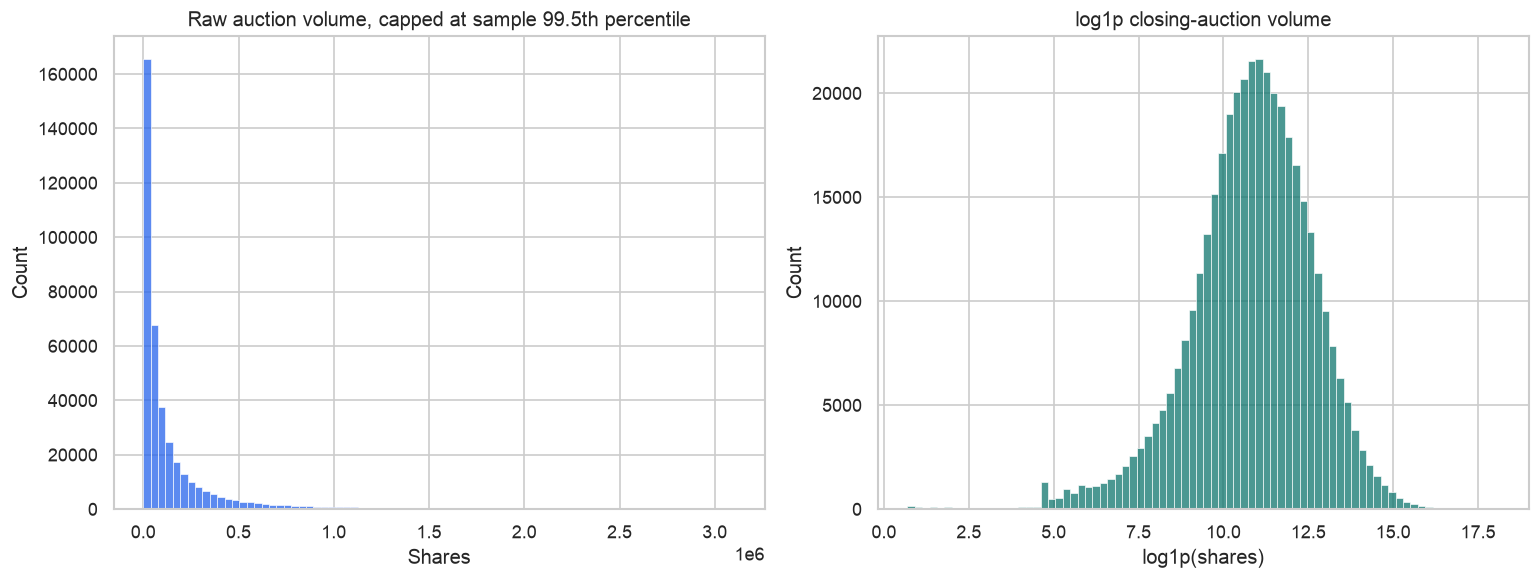

In [4]:
sample = sql("""
SELECT auction_volume, log1p_auction_volume, auction_to_adv20, auction_share_daily_volume
FROM eligible_targets USING SAMPLE 400000 ROWS (reservoir, 20261011)
""")
raw_cap = sample["auction_volume"].quantile(0.995)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(sample.loc[sample["auction_volume"] <= raw_cap, "auction_volume"], bins=80, ax=axes[0], color="#2563eb")
axes[0].set(title="Raw auction volume, capped at sample 99.5th percentile", xlabel="Shares")
sns.histplot(sample["log1p_auction_volume"], bins=80, ax=axes[1], color="#0f766e")
axes[1].set(title="log1p closing-auction volume", xlabel="log1p(shares)")
fig.tight_layout()
fig.savefig(OUT / "target_raw_and_log_distribution.png", bbox_inches="tight")
plt.show()

## Target distribution by year

,year,observations,mean_volume,median_volume,p90_volume,p99_volume,mean_log_volume,median_auction_to_adv20,median_auction_share
0,2015,337566,"111,053.8170","26,179.5000","232,805.0000","1,369,495.4500",10.1624,0.0421,0.0482
1,2016,325638,"123,945.7867","33,463.0000","262,917.9000","1,443,888.9700",10.3357,0.0477,0.0551
2,2017,318040,"132,269.2566","36,875.0000","292,493.9000","1,462,775.4400",10.4284,0.0558,0.0647
3,2018,313807,"171,288.6502","46,948.0000","383,642.2000","1,889,484.3400",10.6858,0.0669,0.0764
4,2019,308240,"181,318.1073","52,923.0000","399,851.0000","1,986,533.1400",10.7951,0.0753,0.0889
5,2020,303168,"214,347.2377","60,827.5000","463,833.1000","2,456,068.1800",10.9531,0.0785,0.0904
6,2021,321564,"180,607.5084","52,176.5000","389,545.0000","2,036,366.8400",10.7288,0.0814,0.0950
7,2022,328634,"194,610.6215","62,564.5000","420,067.1000","2,111,738.7600",10.8807,0.0848,0.0976
8,2023,318679,"220,300.6592","74,877.0000","478,180.0000","2,237,211.5200",11.0787,0.1012,0.1173
9,2024,316212,"259,285.5504","93,278.5000","568,754.9000","2,541,194.0600",11.3036,0.1189,0.1378


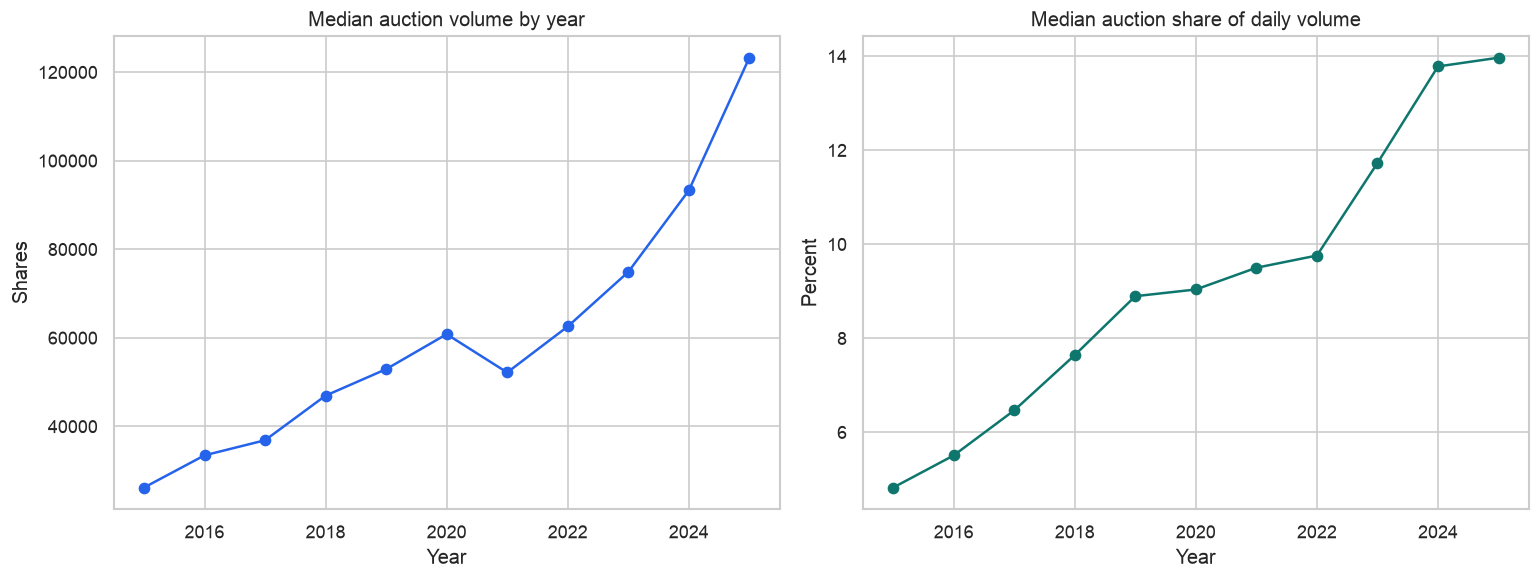

In [5]:
by_year = sql("""
SELECT year, count(*) AS observations,
       avg(auction_volume) AS mean_volume,
       median(auction_volume) AS median_volume,
       quantile_cont(auction_volume, 0.90) AS p90_volume,
       quantile_cont(auction_volume, 0.99) AS p99_volume,
       avg(log1p_auction_volume) AS mean_log_volume,
       median(auction_to_adv20) AS median_auction_to_adv20,
       median(auction_share_daily_volume) AS median_auction_share
FROM eligible_targets GROUP BY 1 ORDER BY 1
""")
display(by_year)
by_year.to_csv(OUT / "target_summary_by_year.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(by_year["year"], by_year["median_volume"], marker="o", color="#2563eb")
axes[0].set(title="Median auction volume by year", xlabel="Year", ylabel="Shares")
axes[1].plot(by_year["year"], 100 * by_year["median_auction_share"], marker="o", color="#0f766e")
axes[1].set(title="Median auction share of daily volume", xlabel="Year", ylabel="Percent")
fig.tight_layout()
fig.savefig(OUT / "target_by_year.png", bbox_inches="tight")
plt.show()

## Market-wide time series

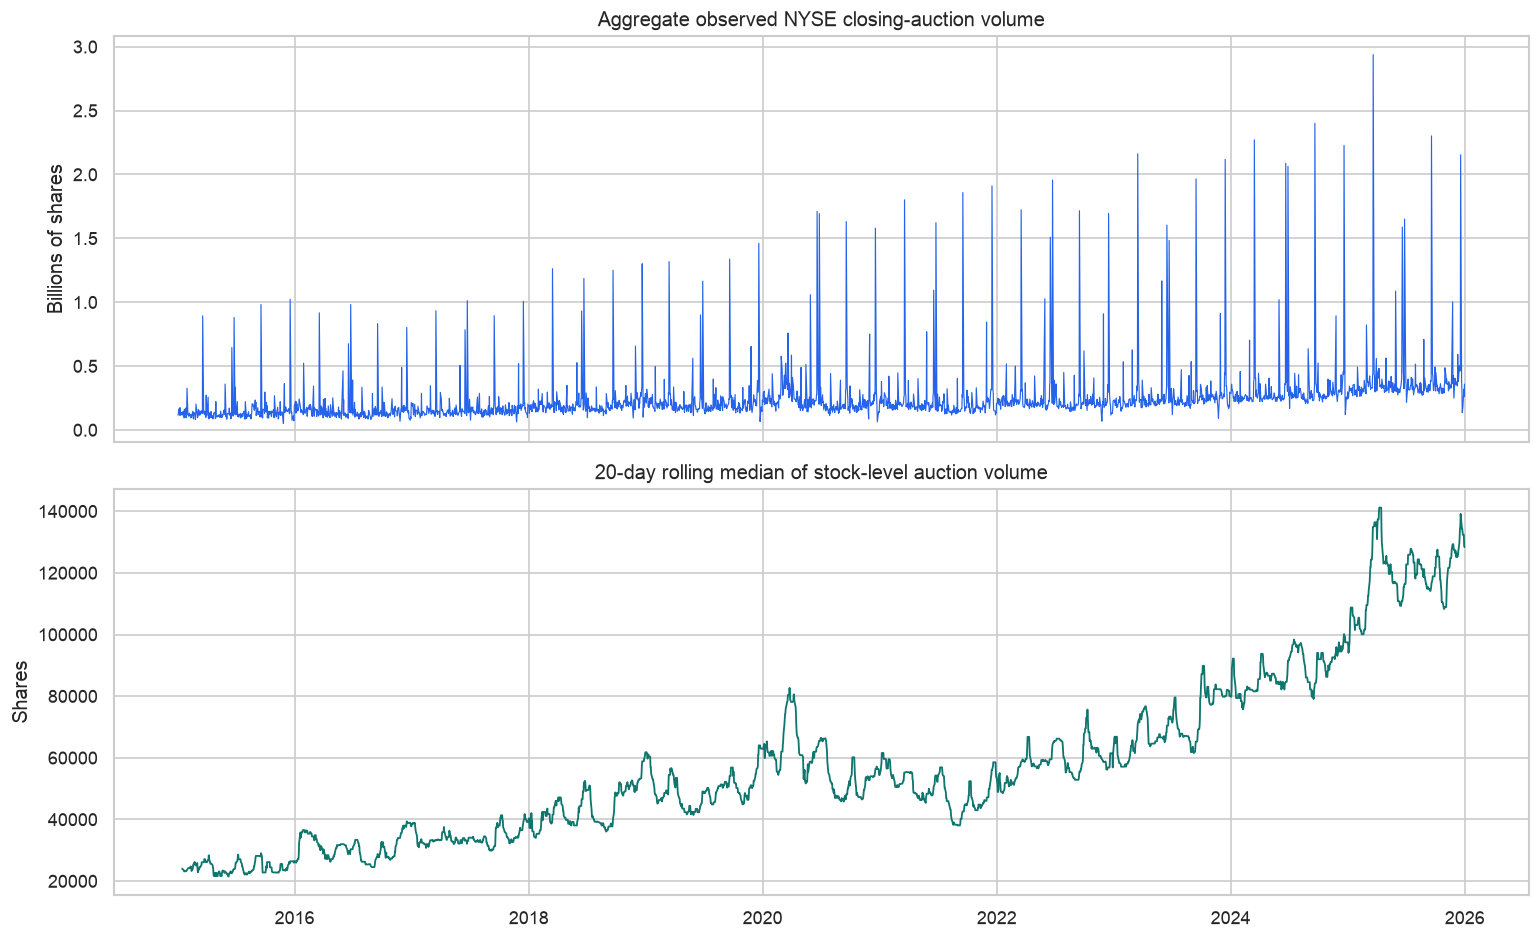

In [6]:
daily_target = sql("""
SELECT date, count(*) AS observed_stocks,
       sum(auction_volume) AS total_auction_volume,
       median(auction_volume) AS median_stock_auction_volume,
       median(auction_share_daily_volume) AS median_auction_share,
       avg(log1p_auction_volume) AS mean_log_volume
FROM eligible_targets GROUP BY 1 ORDER BY 1
""")
daily_target["rolling_20d_median"] = daily_target["median_stock_auction_volume"].rolling(20, min_periods=10).median()
daily_target.to_csv(OUT / "daily_target_summary.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(daily_target["date"], daily_target["total_auction_volume"] / 1e9, linewidth=0.7, color="#2563eb")
axes[0].set(title="Aggregate observed NYSE closing-auction volume", ylabel="Billions of shares")
axes[1].plot(daily_target["date"], daily_target["rolling_20d_median"], linewidth=1.1, color="#0f766e")
axes[1].set(title="20-day rolling median of stock-level auction volume", ylabel="Shares", xlabel="")
fig.tight_layout()
fig.savefig(OUT / "daily_target_time_series.png", bbox_inches="tight")
plt.show()

## Calendar effects

,effect,category,observations,median_volume,mean_log_volume,median_auction_share
0,Day of week,Friday,702860,"63,697.5000",10.9771,0.1007
1,Day of week,Monday,653074,"53,867.5000",10.7733,0.0887
2,Day of week,Thursday,704809,"52,344.0000",10.7388,0.0845
3,Day of week,Tuesday,721115,"53,584.0000",10.7646,0.0864
4,Day of week,Wednesday,717543,"53,651.0000",10.7616,0.0862
5,Last trading day of month,false,3331673,"53,637.0000",10.7744,0.0870
6,Last trading day of month,true,167728,"97,770.0000",11.3737,0.1447
7,Last trading day of quarter,false,3443528,"54,642.0000",10.7935,0.0883
8,Last trading day of quarter,true,55873,"101,309.0000",11.3938,0.1555
9,Monthly options expiry,false,3331842,"53,817.0000",10.7702,0.0877


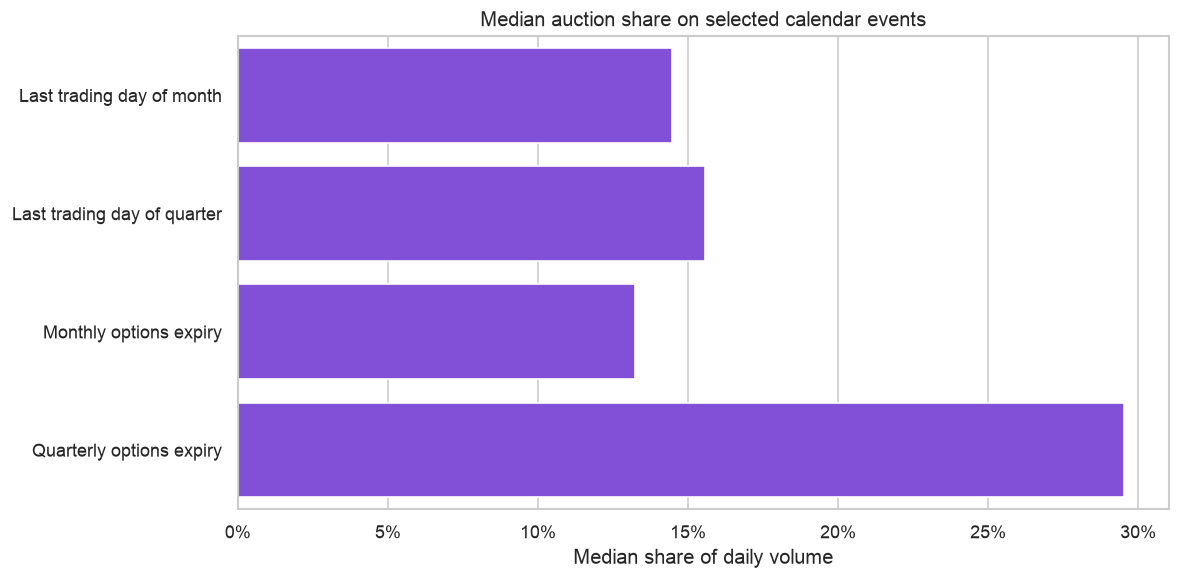

In [7]:
calendar_effects = sql("""
SELECT effect, category, observations, median_volume, mean_log_volume, median_auction_share
FROM (
  SELECT 'Day of week' AS effect,
         CASE day_of_week WHEN 0 THEN 'Monday' WHEN 1 THEN 'Tuesday' WHEN 2 THEN 'Wednesday'
              WHEN 3 THEN 'Thursday' WHEN 4 THEN 'Friday' ELSE cast(day_of_week AS VARCHAR) END AS category,
         count(*) AS observations, median(auction_volume) AS median_volume,
         avg(log1p_auction_volume) AS mean_log_volume,
         median(auction_share_daily_volume) AS median_auction_share
  FROM eligible_targets GROUP BY day_of_week
  UNION ALL
  SELECT 'Last trading day of month', cast(is_last_trading_day_month AS VARCHAR), count(*),
         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)
  FROM eligible_targets GROUP BY is_last_trading_day_month
  UNION ALL
  SELECT 'Last trading day of quarter', cast(is_last_trading_day_quarter AS VARCHAR), count(*),
         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)
  FROM eligible_targets GROUP BY is_last_trading_day_quarter
  UNION ALL
  SELECT 'Monthly options expiry', cast(monthly_options_expiry AS VARCHAR), count(*),
         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)
  FROM eligible_targets GROUP BY monthly_options_expiry
  UNION ALL
  SELECT 'Quarterly options expiry', cast(quarterly_options_expiry AS VARCHAR), count(*),
         median(auction_volume), avg(log1p_auction_volume), median(auction_share_daily_volume)
  FROM eligible_targets GROUP BY quarterly_options_expiry
)
ORDER BY effect, category
""")
display(calendar_effects)
calendar_effects.to_csv(OUT / "calendar_effects.csv", index=False)

binary_effects = calendar_effects[(calendar_effects["effect"] != "Day of week") & (calendar_effects["category"] == "true")].copy()
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=binary_effects, y="effect", x="median_auction_share", color="#7c3aed", ax=ax)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.set(title="Median auction share on selected calendar events", xlabel="Median share of daily volume", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "calendar_event_auction_share.png", bbox_inches="tight")
plt.show()

## Cross-sectional size relationship

,size_decile,observations,median_market_cap,median_auction_volume,mean_log_volume,median_auction_to_adv20,median_auction_share
0,1,351166,"166,454,400.0000","4,350.0000",8.2787,0.0313,0.0398
1,2,350902,"477,851,570.0000","16,209.0000",9.6695,0.0649,0.0774
2,3,350642,"957,495,910.0000","28,182.0000",10.2514,0.0766,0.0895
3,4,350356,"1,615,595,135.0000","38,654.5000",10.5653,0.0800,0.0931
4,5,350084,"2,565,287,010.0000","48,603.0000",10.8198,0.0830,0.0958
5,6,349819,"3,894,564,490.0000","55,653.0000",10.9867,0.0803,0.0921
6,7,349545,"6,051,378,510.0000","68,514.0000",11.1835,0.0777,0.0884
7,8,349250,"10,548,037,350.0000","102,317.5000",11.5320,0.0853,0.0967
8,9,348968,"21,719,364,675.0000","170,940.0000",12.0297,0.0925,0.1037
9,10,348669,"69,259,481,150.0000","354,044.0000",12.7399,0.0955,0.1054


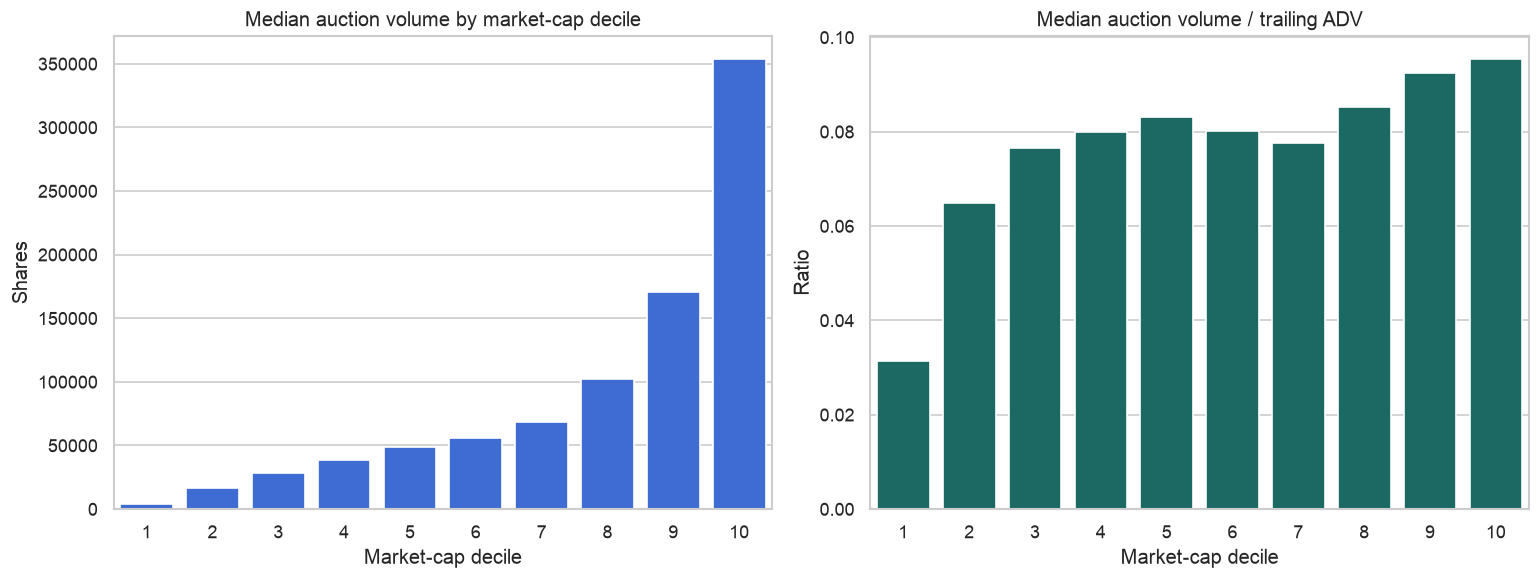

In [8]:
size_deciles = sql("""
WITH ranked AS (
  SELECT *, ntile(10) OVER (PARTITION BY date ORDER BY market_cap_usd) AS size_decile
  FROM eligible_targets WHERE market_cap_usd IS NOT NULL
)
SELECT size_decile, count(*) AS observations,
       median(market_cap_usd) AS median_market_cap,
       median(auction_volume) AS median_auction_volume,
       avg(log1p_auction_volume) AS mean_log_volume,
       median(auction_to_adv20) AS median_auction_to_adv20,
       median(auction_share_daily_volume) AS median_auction_share
FROM ranked GROUP BY 1 ORDER BY 1
""")
display(size_deciles)
size_deciles.to_csv(OUT / "target_by_market_cap_decile.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=size_deciles, x="size_decile", y="median_auction_volume", color="#2563eb", ax=axes[0])
axes[0].set(title="Median auction volume by market-cap decile", xlabel="Market-cap decile", ylabel="Shares")
sns.barplot(data=size_deciles, x="size_decile", y="median_auction_to_adv20", color="#0f766e", ax=axes[1])
axes[1].set(title="Median auction volume / trailing ADV", xlabel="Market-cap decile", ylabel="Ratio")
fig.tight_layout()
fig.savefig(OUT / "target_by_market_cap_decile.png", bbox_inches="tight")
plt.show()

## Industry relationship

,industry,observations,securities,median_auction_volume,mean_log_volume,median_auction_to_adv20,median_auction_share
0,Utilities,175820,97,"117,960.5000",11.5660,0.1024,0.1158
1,Energy,227453,163,"96,484.0000",11.2168,0.0577,0.0653
2,Consumer NonDurables,180761,127,"73,964.0000",10.9128,0.0808,0.0931
3,Healthcare,173545,112,"67,438.0000",11.0890,0.0818,0.0943
4,Chemicals,152677,89,"57,449.0000",10.8196,0.0852,0.0981
5,Business Equipment,374370,303,"55,800.0000",10.8983,0.0717,0.0833
6,Shops,397627,281,"55,592.0000",10.8555,0.0693,0.0796
7,Other,565695,444,"47,828.0000",10.6461,0.0728,0.0843
8,Finance,635121,555,"47,449.0000",10.5200,0.0810,0.0946
9,Manufacturing,435569,256,"45,133.0000",10.6680,0.0865,0.0997


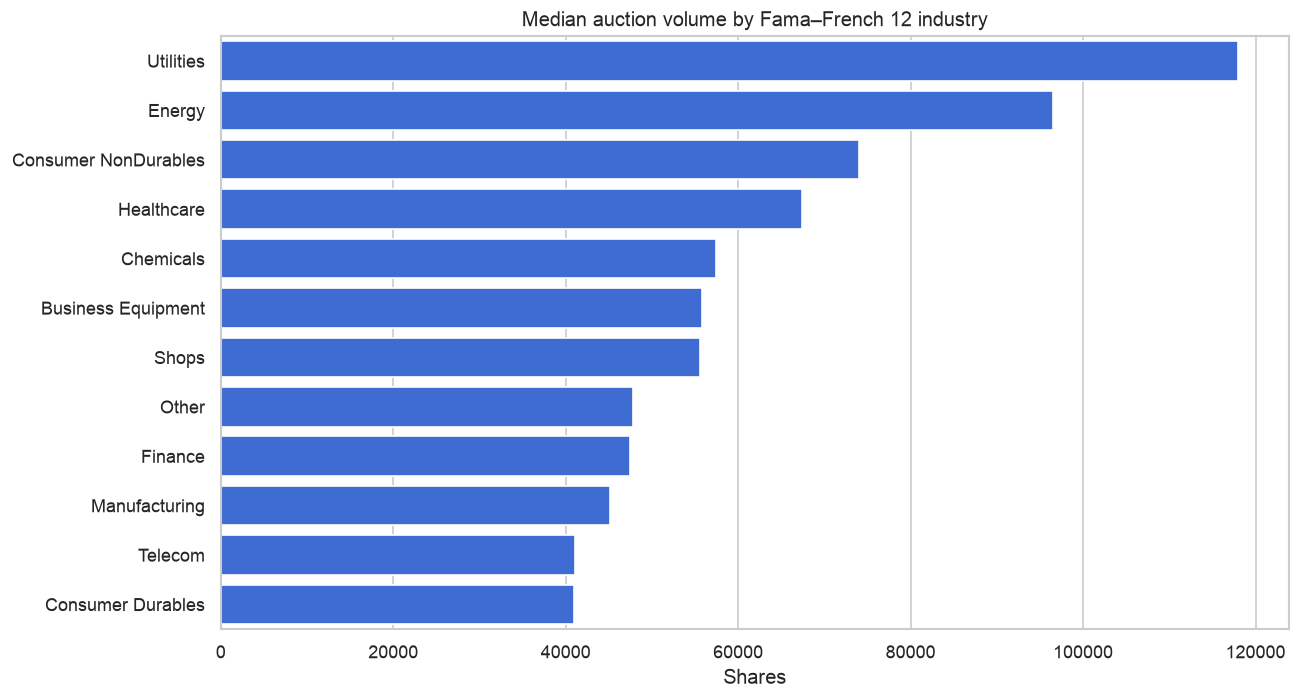

In [9]:
industry = sql(f"""
WITH mapped AS (
  SELECT t.*, i.ff12_code, i.ff12_name,
         row_number() OVER (
           PARTITION BY t.date, t.permno
           ORDER BY i.secinfostartdt DESC, i.secinfoenddt DESC
         ) AS mapping_rank
  FROM eligible_targets t
  LEFT JOIN read_parquet('{INDUSTRY}') i
    ON t.permno = i.permno
   AND t.date BETWEEN i.secinfostartdt AND i.secinfoenddt
)
SELECT coalesce(ff12_name, 'Unmapped') AS industry,
       count(*) AS observations, count(DISTINCT permno) AS securities,
       median(auction_volume) AS median_auction_volume,
       avg(log1p_auction_volume) AS mean_log_volume,
       median(auction_to_adv20) AS median_auction_to_adv20,
       median(auction_share_daily_volume) AS median_auction_share
FROM mapped WHERE mapping_rank = 1
GROUP BY 1 ORDER BY median_auction_volume DESC
""")
display(industry)
industry.to_csv(OUT / "target_by_industry.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=industry, y="industry", x="median_auction_volume", color="#2563eb", ax=ax)
ax.set(title="Median auction volume by Fama–French 12 industry", xlabel="Shares", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "target_by_industry.png", bbox_inches="tight")
plt.show()

## Persistence of the target

,pooled_lag1_correlation,pooled_lag5_correlation,lag1_pairs,lag5_pairs
0,0.8944,0.8806,3497252,3488662


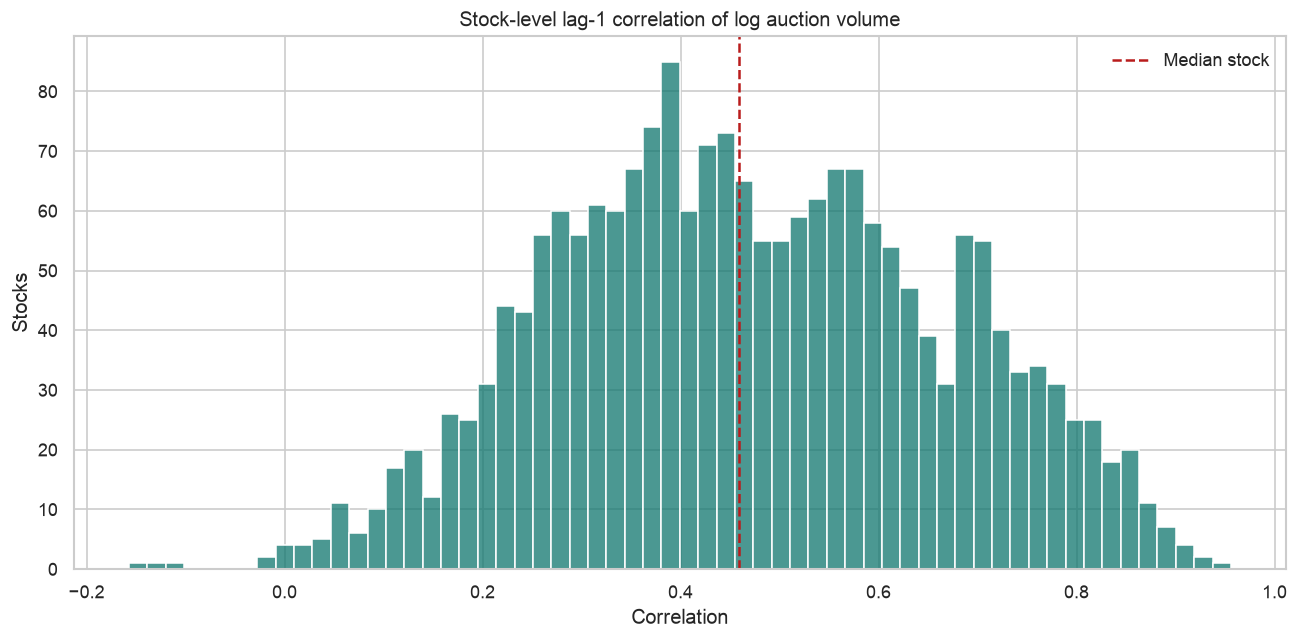

In [10]:
persistence = sql("""
WITH z AS (
  SELECT date, permno, log1p_auction_volume,
         lag(log1p_auction_volume, 1) OVER (PARTITION BY permno ORDER BY date) AS lag1,
         lag(log1p_auction_volume, 5) OVER (PARTITION BY permno ORDER BY date) AS lag5
  FROM eligible_targets
)
SELECT corr(log1p_auction_volume, lag1) AS pooled_lag1_correlation,
       corr(log1p_auction_volume, lag5) AS pooled_lag5_correlation,
       count(*) FILTER (WHERE lag1 IS NOT NULL) AS lag1_pairs,
       count(*) FILTER (WHERE lag5 IS NOT NULL) AS lag5_pairs
FROM z
""")
display(persistence)
persistence.to_csv(OUT / "target_persistence.csv", index=False)

stock_persistence = sql("""
WITH z AS (
  SELECT date, permno, log1p_auction_volume,
         lag(log1p_auction_volume, 1) OVER (PARTITION BY permno ORDER BY date) AS lag1
  FROM eligible_targets
), by_stock AS (
  SELECT permno, count(lag1) AS pairs, corr(log1p_auction_volume, lag1) AS lag1_correlation
  FROM z GROUP BY permno
)
SELECT * FROM by_stock WHERE pairs >= 100 AND lag1_correlation IS NOT NULL
""")
stock_persistence.to_csv(OUT / "stock_level_target_persistence.csv", index=False)

fig, ax = plt.subplots()
sns.histplot(stock_persistence["lag1_correlation"], bins=60, color="#0f766e", ax=ax)
ax.axvline(stock_persistence["lag1_correlation"].median(), color="#b91c1c", linestyle="--", label="Median stock")
ax.set(title="Stock-level lag-1 correlation of log auction volume", xlabel="Correlation", ylabel="Stocks")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "stock_level_target_persistence.png", bbox_inches="tight")
plt.show()

## Compact findings table

In [11]:
headline = pd.DataFrame({
    "finding": [
        "Eligible observations",
        "Median auction volume",
        "99th percentile auction volume",
        "Maximum auction volume",
        "Pooled lag-1 correlation on log scale",
        "Median stock-level lag-1 correlation",
    ],
    "value": [
        int(panel_summary.loc[0, "eligible_rows"]),
        float(distribution.loc[0, "median"]),
        float(distribution.loc[0, "p99"]),
        float(distribution.loc[0, "max"]),
        float(persistence.loc[0, "pooled_lag1_correlation"]),
        float(stock_persistence["lag1_correlation"].median()),
    ],
})
display(headline)
headline.to_csv(OUT / "headline_target_findings.csv", index=False)

,finding,value
0,Eligible observations,"3,499,401.0000"
1,Median auction volume,"55,226.0000"
2,99th percentile auction volume,"2,075,293.0000"
3,Maximum auction volume,"205,378,788.0000"
4,Pooled lag-1 correlation on log scale,0.8944
5,Median stock-level lag-1 correlation,0.4587


## Decisions from this notebook

1. Use `log1p(auction_volume)` as the primary estimation target and translate predictions back to shares for reporting.
2. Keep raw volume and volume-to-trailing-ADV as economic interpretation measures.
3. Always include stock-size controls or stock effects: much of the cross-sectional target difference is scale-related.
4. Preserve calendar flags because closing liquidity changes materially around month-end, quarter-end, and expiry dates.
5. Include lagged auction-volume features because the target is persistent, but measure their value against simple lag and rolling-median baselines.
6. Continue reporting results by year, size decile, industry, and event day; the target distribution is not stationary.